In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
import torch
from torch.utils.data import TensorDataset, DataLoader
import torch.nn as nn
from tqdm.notebook import tqdm
from sklearn.preprocessing import StandardScaler
import joblib
from sklearn.metrics import classification_report, confusion_matrix
import copy
import seaborn as sns


In [2]:
df0404 = pd.read_csv("../data/labeledAndAnomaly/no_plug/0404.csv")
df0712 = pd.read_csv("../data/labeledAndAnomaly/no_plug/0712.csv")
df1703 = pd.read_csv("../data/labeledAndAnomaly/no_plug/1703.csv")
df2906_1 = pd.read_csv("../data/labeledAndAnomaly/no_plug/2906-1.csv")
df3006_1 = pd.read_csv("../data/labeledAndAnomaly/no_plug/3006-1.csv")
df3006_2 = pd.read_csv("../data/labeledAndAnomaly/no_plug/3006-2.csv")

df1103 = pd.read_csv("../data/labeledAndAnomaly/partial_plug/1103.csv")
df1803 = pd.read_csv("../data/labeledAndAnomaly/partial_plug/1803.csv")
df2503 = pd.read_csv("../data/labeledAndAnomaly/partial_plug/2503.csv")
df2108_1 = pd.read_csv("../data/labeledAndAnomaly/partial_plug/2108-1.csv")


df0612_2 = pd.read_csv("../data/labeledAndAnomaly/plug/0612-2.csv")
df0612_3 = pd.read_csv("../data/labeledAndAnomaly/plug/0612-3.csv")
df0707_1 = pd.read_csv("../data/labeledAndAnomaly/plug/0707-1.csv")
df0707_2 = pd.read_csv("../data/labeledAndAnomaly/plug/0707-2.csv")
df0707_4 = pd.read_csv("../data/labeledAndAnomaly/plug/0707-4.csv")
df0709 = pd.read_csv("../data/labeledAndAnomaly/plug/0709.csv")
df1003 = pd.read_csv("../data/labeledAndAnomaly/plug/1003.csv")
df1112 = pd.read_csv("../data/labeledAndAnomaly/plug/1112.csv")
df1310_2 = pd.read_csv("../data/labeledAndAnomaly/plug/1310-2.csv")
df1310_3 = pd.read_csv("../data/labeledAndAnomaly/plug/1310-3.csv")
df1407_1 = pd.read_csv("../data/labeledAndAnomaly/plug/1407-1.csv")
df1407_2 = pd.read_csv("../data/labeledAndAnomaly/plug/1407-2.csv")
df1407_3 = pd.read_csv("../data/labeledAndAnomaly/plug/1407-3.csv")
df1407_4 = pd.read_csv("../data/labeledAndAnomaly/plug/1407-4.csv")
df1503 = pd.read_csv("../data/labeledAndAnomaly/plug/1503.csv")
df1811 = pd.read_csv("../data/labeledAndAnomaly/plug/1811.csv")
df2106_2 = pd.read_csv("../data/labeledAndAnomaly/plug/2106-2.csv")
df2108_2 = pd.read_csv("../data/labeledAndAnomaly/plug/2108-2.csv")
df2701 = pd.read_csv("../data/labeledAndAnomaly/plug/2701.csv")
df2906_2 = pd.read_csv("../data/labeledAndAnomaly/plug/2906-2.csv")
df2906_3 = pd.read_csv("../data/labeledAndAnomaly/plug/2906-3.csv")
df2906_4 = pd.read_csv("../data/labeledAndAnomaly/plug/2906-4.csv")
df3006_3 = pd.read_csv("../data/labeledAndAnomaly/plug/3006-3.csv")

In [3]:
no_plug_dfs = [df0404, df0712, df1703, df2906_1, df3006_1, df3006_2]
plug_dfs =  [df0612_2, df0612_3, df0707_1, df0707_2, df0707_4, df0709, df1003, df1112, df1310_2, df1310_3,
            df1407_1, df1407_2, df1407_3, df1407_4, df1503, df1811, df2106_2, df2108_2, df2701, 
            df2906_2, df2906_3, df2906_4, df3006_3]
partial_plug_dfs = [df1103, df1803, df2503, df2108_1]

In [59]:
df0404.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18918 entries, 0 to 18917
Data columns (total 22 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   elapsed_runtime_s             18918 non-null  float64
 1   Temperature TS inlet (Mean)   18918 non-null  float64
 2   Temperature TS outlet (Mean)  18918 non-null  float64
 3   Tank temperature (Mean)       18918 non-null  float64
 4   Bypass temperature (Mean)     18918 non-null  float64
 5   Pump outlet pressure (Mean)   18918 non-null  float64
 6   TS inlet pressure (Mean)      18918 non-null  float64
 7   TS outlet pressure (Mean)     18918 non-null  float64
 8   Differential pressure (Mean)  18918 non-null  float64
 9   Pump to inlet DP              18918 non-null  float64
 10  Total system DP               18918 non-null  float64
 11  Flow rate (Mean)              18918 non-null  float64
 12  Pressure_Ratio                18918 non-null  float64
 13  R

In [4]:

FINAL_FEATURES = [
    'rel_tot_dp_change', 
    'rel_ts_dp_change', 
    'rel_p_ts_dp_change', 
    'Relative_Ratio_Dev', 
    'anomaly_score'
]

WINDOW_SIZE = 60

In [8]:
runs = {}   # id(df) -> (df, run_type)
for df in no_plug_dfs:      runs[id(df)] = (df, 'no_plug')
for df in plug_dfs:         runs[id(df)] = (df, 'plug')
for df in partial_plug_dfs: runs[id(df)] = (df, 'partial') 

run_list  = [v[0] for v in runs.values()]
run_types = np.array([v[1] for v in runs.values()])
idx = np.arange(len(run_list))

# Split runs, stratified by run type
train_idx = [0,2,5,6,7,10,12,13,15,16,17,19,21,22,25,28,29,31]
val_idx   = [1,9,11,18,23,26,27,30]
test_idx  = [3,4,8,14,20,24,32]

pick = lambda ids: [run_list[i] for i in ids]
X_train, y_train = build_lstm_matrices(pick(train_idx), FINAL_FEATURES, WINDOW_SIZE)
X_val,   y_val   = build_lstm_matrices(pick(val_idx),   FINAL_FEATURES, WINDOW_SIZE)
X_test,  y_test  = build_lstm_matrices(pick(test_idx),  FINAL_FEATURES, WINDOW_SIZE)

# Check what each split actually contains
for name, y in [('train', y_train), ('val', y_val), ('test', y_test)]:
    print(name, np.bincount(y, minlength=4))

train [59294 11225 36149  6053]
val [15633  5720 11161  1930]
test [8580 1495 5836 2823]


In [34]:
n_samples_train, n_timesteps, n_features = X_train.shape
n_samples_val = X_val.shape[0]
n_samples_test = X_test.shape[0]

X_train_flat = X_train.reshape(-1, n_features)
X_val_flat   = X_val.reshape(-1, n_features)
X_test_flat  = X_test.reshape(-1, n_features)

lstm_scaler = StandardScaler()
X_train_scaled_flat = lstm_scaler.fit_transform(X_train_flat)

X_val_scaled_flat   = lstm_scaler.transform(X_val_flat)
X_test_scaled_flat  = lstm_scaler.transform(X_test_flat)

X_train_scaled = X_train_scaled_flat.reshape(n_samples_train, n_timesteps, n_features)
X_val_scaled   = X_val_scaled_flat.reshape(n_samples_val, n_timesteps, n_features)
X_test_scaled  = X_test_scaled_flat.reshape(n_samples_test, n_timesteps, n_features)

joblib.dump(lstm_scaler, '../models/lstm_scaler.joblib')


['../models/lstm_scaler.joblib']

In [35]:
X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.long)

X_val_t = torch.tensor(X_val_scaled, dtype=torch.float32)
y_val_t = torch.tensor(y_val, dtype=torch.long)

X_test_t = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_t = torch.tensor(y_test, dtype=torch.long)

BATCH_SIZE = 128

train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(TensorDataset(X_val_t, y_val_t), batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(TensorDataset(X_test_t, y_test_t), batch_size=BATCH_SIZE, shuffle=False)

print(f"Training Batches:   {len(train_loader)}")
print(f"Validation Batches: {len(val_loader)}")
print(f"Test Batches:       {len(test_loader)}")

Training Batches:   727
Validation Batches: 221
Test Batches:       349


In [36]:
BATCH_SIZE = 128

train_dataset = TensorDataset(X_train_t, y_train_t)
val_dataset = TensorDataset(X_val_t, y_val_t)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"Number of training batches per epoch: {len(train_loader)}")

Number of training batches per epoch: 727


In [37]:
class HydraulicLSTM(nn.Module):
    def __init__(self, input_dim, hidden_dim, num_layers, num_classes):
        super(HydraulicLSTM, self).__init__()
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers

        self.lstm = nn.LSTM(
            input_size=input_dim, 
            hidden_size=hidden_dim, 
            num_layers=num_layers, 
            batch_first=True,
            dropout=0.2 if num_layers > 1 else 0.0
        )
        
        self.fc = nn.Linear(hidden_dim, num_classes)
        
    def forward(self, x):
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_dim).to(x.device)
        c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_dim).to(x.device)

        out, _ = self.lstm(x, (h0, c0))

        last_time_step_output = out[:, -1, :]

        logits = self.fc(last_time_step_output)
        return logits

In [42]:
INPUT_DIM = 5   
HIDDEN_DIM = 16  
NUM_LAYERS = 1   
NUM_CLASSES = 4  

model = HydraulicLSTM(INPUT_DIM, HIDDEN_DIM, NUM_LAYERS, NUM_CLASSES)

criterion = nn.CrossEntropyLoss() 
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=2
)

print(model)

HydraulicLSTM(
  (lstm): LSTM(5, 16, batch_first=True)
  (fc): Linear(in_features=16, out_features=4, bias=True)
)


In [43]:
device = torch.device('cpu')
model = model.to(device)

def train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, max_epochs, patience):
    device = torch.device('cpu')
    model = model.to(device)
    
    best_val_loss = float('inf')
    epochs_no_improve = 0
    best_epoch = 0
    
    print(f"Adaptive Training Loop started on: {device}\n")
    
    for epoch in range(max_epochs):
        current_lr = optimizer.param_groups[0]['lr']
        
        model.train()
        running_loss, correct_train, total_train = 0.0, 0, 0
        
        # Create a dynamic text-based progress bar for training batches
        train_bar = tqdm(train_loader, desc=f"Epoch {epoch+1:02d}/{max_epochs:02d} [Train] (LR: {current_lr:.6f})", leave=True)
        
        for batch_X, batch_y in train_bar:
            batch_X, batch_y = batch_X.to(device), batch_y.to(device)
            
            outputs = model(batch_X)
            loss = criterion(outputs, batch_y)
            
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            
            running_loss += loss.item() * batch_X.size(0)
            _, predicted = torch.max(outputs, 1)
            total_train += batch_y.size(0)
            correct_train += (predicted == batch_y).sum().item()
            
            batch_acc = (predicted == batch_y).sum().item() / batch_y.size(0)
            train_bar.set_postfix({'loss': f"{loss.item():.4f}", 'acc': f"{batch_acc*100:.1f}%"})
            
        epoch_train_loss = running_loss / total_train
        epoch_train_acc = correct_train / total_train

        model.eval()
        val_loss, correct_val, total_val = 0.0, 0, 0
        
        # Progress bar for validation batches
        val_bar = tqdm(val_loader, desc=f"Epoch {epoch+1:02d}/{max_epochs:02d} [Valid]", leave=False)
        
        with torch.no_grad():
            for batch_X, batch_y in val_bar:
                batch_X, batch_y = batch_X.to(device), batch_y.to(device)
                outputs = model(batch_X)
                loss = criterion(outputs, batch_y)
                
                val_loss += loss.item() * batch_X.size(0)
                _, predicted = torch.max(outputs, 1)
                total_val += batch_y.size(0)
                correct_val += (predicted == batch_y).sum().item()
                
                val_bar.set_postfix({'loss': f"{loss.item():.4f}"})
                
        epoch_val_loss = val_loss / total_val
        epoch_val_acc = correct_val / total_val

        print(f" Epoch [{epoch+1:02d}/{max_epochs:02d}] Summary:")
        print(f" [TRAIN] Loss: {epoch_train_loss:.4f} | Acc: {epoch_train_acc*100:.2f}%")
        print(f" [VALID] Loss: {epoch_val_loss:.4f} | Acc: {epoch_val_acc*100:.2f}%")
        
        scheduler.step(epoch_val_loss)

        if epoch_val_loss < best_val_loss:
            best_val_loss = epoch_val_loss
            best_epoch = epoch + 1
            epochs_no_improve = 0
            torch.save(model.state_dict(), '../models/best_hydraulic_lstm.pth')
            print(f"   New Best Val Loss! Weights saved to 'best_hydraulic_lstm.pth'")
        else:
            epochs_no_improve += 1
            print(f"   No improvement in val loss for {epochs_no_improve} epoch(s).")
            
        print("=" * 70)

        if epochs_no_improve >= patience:
            print(f"\n Early Stopping Triggered! No improvement for {patience} epochs.")
            print(f"Best configuration at Epoch {best_epoch} with Val Loss: {best_val_loss:.4f}")
            break
            
    model.load_state_dict(torch.load('../models/best_hydraulic_lstm.pth'))
    print("\n Best model configuration successfully re-loaded into memory!")
    return model

In [21]:
best_model.eval()

test_predictions = []
test_true_labels = []

with torch.no_grad():
    for batch_X, batch_y in test_loader:
        batch_X = batch_X.to(device)
        
        # Forward pass to get raw scores
        outputs = best_model(batch_X)
        
        # Get the index of the highest score
        _, predicted = torch.max(outputs, 1)
        
        test_predictions.extend(predicted.cpu().numpy())
        test_true_labels.extend(batch_y.numpy())

y_pred = np.array(test_predictions)
y_true = np.array(test_true_labels)

In [24]:
from sklearn.model_selection import StratifiedGroupKFold

X_all, y_all, groups = [], [], []
for g, df in enumerate(run_list):
    X, y = build_lstm_matrices([df], FINAL_FEATURES, WINDOW_SIZE)
    X_all.append(X); y_all.append(y)
    groups.append(np.full(len(y), g))          # one group per run
X_all, y_all, groups = map(np.concatenate, (X_all, y_all, groups))

def make_folds(seed, n_outer=5, n_inner=4):
    outer = StratifiedGroupKFold(n_splits=n_outer, shuffle=True, random_state=seed)
    folds = []
    for trv, te in outer.split(X_all, y_all, groups):
        inner = StratifiedGroupKFold(n_splits=n_inner, shuffle=True, random_state=seed)
        tr_rel, va_rel = next(inner.split(X_all[trv], y_all[trv], groups[trv]))
        folds.append((trv[tr_rel], trv[va_rel], te))
    return folds

def show(folds):
    for k, (tr, va, te) in enumerate(folds):
        assert not (set(groups[tr]) & set(groups[va]) | set(groups[tr]) & set(groups[te]) | set(groups[va]) & set(groups[te]))
        print(f"fold {k}")
        for name, i in [('train', tr), ('val', va), ('test', te)]:
            c = np.bincount(y_all[i], minlength=4)
            print(f"  {name:5s} {c}  {np.round(c/c.sum(), 2)}  dates={len(set(groups[i]))}")

for seed in range(5):
    print(f"=== seed {seed} ===")
    show(make_folds(seed))

=== seed 0 ===
fold 0
  train [64172 12670 20820  7859]  [0.61 0.12 0.2  0.07]  dates=23
  val   [ 5768  5160 21836   873]  [0.17 0.15 0.65 0.03]  dates=5
  test  [13567   610 10490  2074]  [0.51 0.02 0.39 0.08]  dates=5
fold 1
  train [72430  7545 28185  7511]  [0.63 0.07 0.24 0.06]  dates=19
  val   [ 9492  9510 20241  1919]  [0.23 0.23 0.49 0.05]  dates=7
  test  [1585 1385 4720 1376]  [0.17 0.15 0.52 0.15]  dates=7
fold 2
  train [43027 11550 43758  4231]  [0.42 0.11 0.43 0.04]  dates=17
  val   [22355   640   705  1123]  [0.9  0.03 0.03 0.05]  dates=7
  test  [18125  6250  8683  5452]  [0.47 0.16 0.23 0.14]  dates=9
fold 3
  train [44857  7835 13849  6102]  [0.62 0.11 0.19 0.08]  dates=21
  val   [16038  5560 20211  3641]  [0.35 0.12 0.44 0.08]  dates=5
  test  [22612  5045 19086  1063]  [0.47 0.11 0.4  0.02]  dates=7
fold 4
  train [47097  7790 37114  8263]  [0.47 0.08 0.37 0.08]  dates=23
  val   [8792 5500 5865 1702]  [0.4  0.25 0.27 0.08]  dates=5
  test  [27618  5150 10167   

In [25]:
def seed_quality(folds):
    n = len(y_all)
    worst_cls  = min(np.bincount(y_all[i], minlength=4).min()
                     for tr, va, te in folds for i in (va, te))
    min_train  = min(len(tr) for tr, va, te in folds) / n
    max_test   = max(len(te) for tr, va, te in folds) / n
    return worst_cls, min_train, max_test

good = []
for seed in range(100):
    wc, mt, xt = seed_quality(make_folds(seed))
    if mt >= 0.55 and xt <= 0.30:            # train never too small, no huge test fold
        good.append((wc, seed, round(mt, 2), round(xt, 2)))
for row in sorted(good, reverse=True)[:5]:
    print(row)   # (worst class count in any val/test, seed, min train frac, max test frac)

(np.int64(735), 35, 0.61, 0.25)
(np.int64(490), 80, 0.66, 0.28)
(np.int64(395), 21, 0.58, 0.27)
(np.int64(335), 84, 0.64, 0.25)


In [26]:
folds = make_folds(35)
show(folds)

fold 0
  train [57221 12905 33635  8668]  [0.51 0.11 0.3  0.08]  dates=23
  val   [ 2920  4800 18146  1206]  [0.11 0.18 0.67 0.04]  dates=5
  test  [23366   735  1365   932]  [0.89 0.03 0.05 0.04]  dates=5
fold 1
  train [49758 15575 31903  3332]  [0.49 0.15 0.32 0.03]  dates=20
  val   [12275  1555  9768  1046]  [0.5  0.06 0.4  0.04]  dates=6
  test  [21474  1310 11475  6428]  [0.53 0.03 0.28 0.16]  dates=7
fold 2
  train [59352  7280 26706  7106]  [0.59 0.07 0.27 0.07]  dates=18
  val   [ 1735  5150 18341  2057]  [0.06 0.19 0.67 0.08]  dates=6
  test  [22420  6010  8099  1643]  [0.59 0.16 0.21 0.04]  dates=9
fold 3
  train [77552 12415 23510  6092]  [0.65 0.1  0.2  0.05]  dates=21
  val   [ 3900  1260 11380  3879]  [0.19 0.06 0.56 0.19]  dates=5
  test  [ 2055  4765 18256   835]  [0.08 0.18 0.7  0.03]  dates=7
fold 4
  train [67760 11760 38330  7646]  [0.54 0.09 0.31 0.06]  dates=23
  val   [1555 1060  865 2192]  [0.27 0.19 0.15 0.39]  dates=5
  test  [14192  5620 13951   968]  [0.41

In [27]:
import copy
import numpy as np, pandas as pd, torch, torch.nn as nn, joblib
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score, recall_score, confusion_matrix
from torch.utils.data import DataLoader, TensorDataset

# run_list = your 33 unique runs, in the same order as your label table
X_all, y_all, groups = [], [], []
for g, df in enumerate(run_list):
    X, y = build_lstm_matrices([df], FINAL_FEATURES, WINDOW_SIZE)
    X_all.append(X); y_all.append(y); groups.append(np.full(len(y), g))
X_all, y_all, groups = map(np.concatenate, (X_all, y_all, groups))
print(X_all.shape, y_all.shape, len(np.unique(groups)), "runs")

(165899, 60, 5) (165899,) 33 runs


In [28]:
def make_folds(seed, n_outer=5, n_inner=4):
    outer = StratifiedGroupKFold(n_splits=n_outer, shuffle=True, random_state=seed)
    folds = []
    for trv, te in outer.split(X_all, y_all, groups):
        inner = StratifiedGroupKFold(n_splits=n_inner, shuffle=True, random_state=seed)
        tr_rel, va_rel = next(inner.split(X_all[trv], y_all[trv], groups[trv]))
        folds.append((trv[tr_rel], trv[va_rel], te))
    return folds

folds = make_folds(35)
joblib.dump({'seed': 35, 'folds': folds}, '../models/cv_folds_seed35.joblib')

for k, (tr, va, te) in enumerate(folds):   # no run may be in two sets
    assert not (set(groups[tr]) & set(groups[va]))
    assert not (set(groups[tr]) & set(groups[te]))
    assert not (set(groups[va]) & set(groups[te]))

In [29]:
def scale(scaler, X):
    n, t, f = X.shape
    return scaler.transform(X.reshape(-1, f)).reshape(n, t, f)

def make_loader(X, y, shuffle):
    ds = TensorDataset(torch.tensor(X, dtype=torch.float32),
                       torch.tensor(y, dtype=torch.long))
    return DataLoader(ds, batch_size=128, shuffle=shuffle)

def predict(model, X, batch=1024):
    model.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(X), batch):
            out.append(model(torch.tensor(X[i:i+batch], dtype=torch.float32)).argmax(1))
    return torch.cat(out).numpy()

def train_fold(model, train_loader, val_loader, criterion, optimizer, scheduler,
               max_epochs=100, patience=8):
    best_loss, best_state, best_epoch, bad = float('inf'), None, 0, 0
    for epoch in range(1, max_epochs + 1):
        model.train(); tl, tn = 0.0, 0
        for xb, yb in train_loader:
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            tl += loss.item() * len(yb); tn += len(yb)

        model.eval(); vl, vn = 0.0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                vl += criterion(model(xb), yb).item() * len(yb); vn += len(yb)
        vl /= vn
        scheduler.step(vl)

        if vl < best_loss:
            best_loss, best_epoch, bad = vl, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            bad += 1
        print(f"  epoch {epoch:3d} | train {tl/tn:.4f} | val {vl:.4f} | best ep {best_epoch}")
        if bad >= patience:
            break
    model.load_state_dict(best_state)
    return model, best_epoch

In [30]:
STRIDE = 1          # thin the TRAINING windows only (neighbouring windows are near-duplicates)
results = []

for k, (tr, va, te) in enumerate(folds):
    print(f"\n===== Fold {k} =====")
    torch.manual_seed(k); np.random.seed(k)

    tr = tr[::STRIDE]
    scaler = StandardScaler().fit(X_all[tr].reshape(-1, X_all.shape[2]))   # train only
    Xtr, Xva, Xte = (scale(scaler, X_all[i]) for i in (tr, va, te))
    ytr, yva, yte = y_all[tr], y_all[va], y_all[te]

    counts = np.bincount(ytr, minlength=4)
    w = torch.tensor(len(ytr) / (4 * np.maximum(counts, 1)), dtype=torch.float32)
    criterion = nn.CrossEntropyLoss(weight=w)

    model = HydraulicLSTM(INPUT_DIM, HIDDEN_DIM, NUM_LAYERS, NUM_CLASSES)   # fresh each fold
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, 'min', factor=0.5, patience=2)

    model, best_epoch = train_fold(model, make_loader(Xtr, ytr, True),
                                   make_loader(Xva, yva, False),
                                   criterion, optimizer, scheduler)

    torch.save(model.state_dict(), f'../models/lstm_fold{k}.pth')
    joblib.dump(scaler, f'../models/scaler_fold{k}.joblib')

    pred = predict(model, Xte)
    results.append(dict(
        fold=k,
        best_epoch=best_epoch,
        macro_f1=f1_score(yte, pred, average='macro'),
        binary_f1=f1_score(yte > 0, pred > 0),
        within1=(np.abs(pred - yte) <= 1).mean(),
        **{f'recall_c{c}': r for c, r in
           enumerate(recall_score(yte, pred, labels=[0,1,2,3], average=None, zero_division=0))},
        cm=confusion_matrix(yte, pred, labels=[0,1,2,3]),
        test_runs=sorted(set(groups[te])),
    ))
    r = results[-1]
    print(f"  -> macro-F1 {r['macro_f1']:.3f} | binary-F1 {r['binary_f1']:.3f} | within±1 {r['within1']:.3f}")


===== Fold 0 =====
  epoch   1 | train 0.5371 | val 3.9214 | best ep 1
  epoch   2 | train 0.3154 | val 4.0956 | best ep 1
  epoch   3 | train 0.2680 | val 3.5956 | best ep 3
  epoch   4 | train 0.2287 | val 5.0908 | best ep 3
  epoch   5 | train 0.2099 | val 5.9227 | best ep 3
  epoch   6 | train 0.1888 | val 5.9744 | best ep 3
  epoch   7 | train 0.1544 | val 6.6590 | best ep 3
  epoch   8 | train 0.1331 | val 6.2958 | best ep 3
  epoch   9 | train 0.1252 | val 5.9548 | best ep 3
  epoch  10 | train 0.1022 | val 6.6232 | best ep 3
  epoch  11 | train 0.0949 | val 6.7358 | best ep 3
  -> macro-F1 0.283 | binary-F1 0.284 | within±1 0.622

===== Fold 1 =====
  epoch   1 | train 0.5323 | val 1.5891 | best ep 1
  epoch   2 | train 0.2616 | val 1.3945 | best ep 2
  epoch   3 | train 0.1966 | val 1.3294 | best ep 3
  epoch   4 | train 0.1676 | val 0.9733 | best ep 4
  epoch   5 | train 0.1505 | val 0.7605 | best ep 5
  epoch   6 | train 0.1308 | val 0.7967 | best ep 5
  epoch   7 | train 0

In [31]:
summary = pd.DataFrame([{k: v for k, v in r.items() if k not in ('cm', 'test_runs')} for r in results])
print(summary.round(3).to_string(index=False))
print("\nmean ± std")
print(pd.DataFrame({'mean': summary.mean(), 'std': summary.std()}).round(3))

for r in results:
    print(f"\nFold {r['fold']}  test runs: {r['test_runs']}")
    print(r['cm'])

 fold  best_epoch  macro_f1  binary_f1  within1  recall_c0  recall_c1  recall_c2  recall_c3
    0           3     0.283      0.284    0.622      0.378      0.101      0.131      1.000
    1           7     0.372      0.969    0.972      0.987      0.119      0.064      0.401
    2           1     0.294      0.884    0.959      0.881      0.020      0.021      0.561
    3           1     0.380      0.982    0.986      0.821      0.487      0.037      0.756
    4           5     0.244      0.432    0.685      0.653      0.149      0.146      0.187

mean ± std
             mean    std
fold        2.000  1.581
best_epoch  3.400  2.608
macro_f1    0.314  0.059
binary_f1   0.710  0.328
within1     0.845  0.176
recall_c0   0.744  0.238
recall_c1   0.175  0.181
recall_c2   0.080  0.056
recall_c3   0.581  0.314

Fold 0  test runs: [np.int64(0), np.int64(1), np.int64(24), np.int64(25), np.int64(27)]
[[8824 5110 9432    0]
 [ 122   74    0  539]
 [   7   45  179 1134]
 [   0    0    0  932]]

Fol

In [33]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import joblib

# 1. Clean unique run definitions (removing duplicates)
no_plug_dfs = [df0404, df0712, df1703, df2906_1, df3006_1, df3006_2]
partial_plug_dfs = [df1103, df1803, df2503, df2108_1]
plug_dfs = [
    df0612_2, df0612_3, df0707_1, df0707_2, df0707_4, df0709, df1003, 
    df1112, df1310_2, df1310_3, df1407_1, df1407_2, df1407_3, df1407_4, 
    df1503, df1811, df2106_2, df2108_2, df2701, df2906_2, df2906_3, 
    df2906_4, df3006_3
]

# 2. Pair each run list with a categorical label for run-level stratification
# 0 = Normal, 1 = Partial Plug Run, 2 = Severe/Full Plug Run
run_tuples = []
for df in no_plug_dfs:
    run_tuples.append((df, 0))
for df in partial_plug_dfs:
    run_tuples.append((df, 1))
for df in plug_dfs:
    run_tuples.append((df, 2))

dfs_all = [t[0] for t in run_tuples]
run_categories = [t[1] for t in run_tuples]

# 3. Stratified Split at the RUN level (80% TrainVal, 20% Test)
trainval_dfs, test_dfs, trainval_cats, test_cats = train_test_split(
    dfs_all, run_categories, test_size=0.20, random_state=42, stratify=run_categories
)

# Stratified Split TrainVal into Train (80%) and Validation (20%)
train_dfs, val_dfs, _, _ = train_test_split(
    trainval_dfs, trainval_cats, test_size=0.20, random_state=42, stratify=trainval_cats
)

print(f"Total Runs: {len(dfs_all)} | Train Runs: {len(train_dfs)} | Val Runs: {len(val_dfs)} | Test Runs: {len(test_dfs)}")

# 4. Now generate 60-second sliding windows independently for each set
FINAL_FEATURES = [
    'rel_tot_dp_change', 
    'rel_ts_dp_change', 
    'rel_p_ts_dp_change', 
    'Relative_Ratio_Dev', 
    'anomaly_score'
]
WINDOW_SIZE = 60

def build_lstm_matrices(list_of_dfs, features, window_size=60):
    X_list, y_list = [], []
    for df in list_of_dfs:
        data = df[features].values
        labels = df['label'].values
        
        for i in range(window_size, len(data)):
            X_list.append(data[i - window_size : i])
            y_list.append(labels[i])

    return np.array(X_list), np.array(y_list)

X_train, y_train = build_lstm_matrices(train_dfs, FINAL_FEATURES, WINDOW_SIZE)
X_val, y_val     = build_lstm_matrices(val_dfs, FINAL_FEATURES, WINDOW_SIZE)
X_test, y_test   = build_lstm_matrices(test_dfs, FINAL_FEATURES, WINDOW_SIZE)

print(f"\nWindow Counts -> Train: {X_train.shape[0]}, Val: {X_val.shape[0]}, Test: {X_test.shape[0]}")

Total Runs: 33 | Train Runs: 20 | Val Runs: 6 | Test Runs: 7

Window Counts -> Train: 93050, Val: 28283, Test: 44566


In [50]:
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupKFold

# 1. Clean run lists (duplicates removed)
no_plug_dfs = [df0404, df0712, df1703, df2906_1, df3006_1, df3006_2]
partial_plug_dfs = [df1103, df1803, df2503, df2108_1]
plug_dfs = [
    df0612_2, df0612_3, df0707_1, df0707_2, df0707_4, df0709, df1003, 
    df1112, df1310_2, df1310_3, df1407_1, df1407_2, df1407_3, df1407_4, 
    df1503, df1811, df2106_2, df2108_2, df2701, df2906_2, df2906_3, 
    df2906_4, df3006_3
]

# Combine all unique DataFrames
all_runs = no_plug_dfs + partial_plug_dfs + plug_dfs

# 2. Assign unique run_id integer to each DataFrame in place
for idx, df in enumerate(all_runs):
    df['run_id'] = idx

# 3. Builder function that extracts window arrays AND matching run_ids
def build_lstm_matrices_with_groups(list_of_dfs, features, window_size=60):
    X_list, y_list, groups_list = [], [], []
    for df in list_of_dfs:
        data = df[features].values
        labels = df['label'].values
        run_ids = df['run_id'].values
        
        for i in range(window_size, len(data)):
            X_list.append(data[i - window_size : i])
            y_list.append(labels[i])
            groups_list.append(run_ids[i])

    return np.array(X_list), np.array(y_list), np.array(groups_list)

FINAL_FEATURES = [
    'rel_tot_dp_change', 
    'rel_ts_dp_change', 
    'rel_p_ts_dp_change', 
    'Relative_Ratio_Dev', 
    'anomaly_score'
]
WINDOW_SIZE = 60

X_all, y_all, groups_all = build_lstm_matrices_with_groups(all_runs, FINAL_FEATURES, WINDOW_SIZE)

# 4. Verify class distribution across all 5 folds
gkf = GroupKFold(n_splits=5)
for fold, (train_idx, val_idx) in enumerate(gkf.split(X_all, y_all, groups=groups_all)):
    y_va = y_all[val_idx]
    print(f"Fold {fold+1} Validation Samples: {len(y_va)}")
    print(f"Class Proportions: {pd.Series(y_va).value_counts(normalize=True).round(3).to_dict()}")
    print("-" * 65)

Fold 1 Validation Samples: 33310
Class Proportions: {2: 0.552, 0: 0.238, 1: 0.149, 3: 0.061}
-----------------------------------------------------------------
Fold 2 Validation Samples: 33101
Class Proportions: {0: 0.413, 2: 0.332, 1: 0.166, 3: 0.089}
-----------------------------------------------------------------
Fold 3 Validation Samples: 33103
Class Proportions: {0: 0.777, 2: 0.14, 3: 0.049, 1: 0.034}
-----------------------------------------------------------------
Fold 4 Validation Samples: 33152
Class Proportions: {0: 0.705, 1: 0.167, 2: 0.093, 3: 0.035}
-----------------------------------------------------------------
Fold 5 Validation Samples: 33233
Class Proportions: {2: 0.483, 0: 0.386, 3: 0.09, 1: 0.04}
-----------------------------------------------------------------


In [51]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Container for overall Out-Of-Fold predictions
oof_preds = np.zeros(len(y_all))
oof_targets = np.zeros(len(y_all))

# Hyperparameters
BATCH_SIZE = 128
EPOCHS = 15
LR = 0.001

for fold, (train_idx, val_idx) in enumerate(gkf.split(X_all, y_all, groups=groups_all)):
    print(f"\n==================== FOLD {fold+1} / 5 ====================")
    
    # 1. Slice Fold Data
    X_tr_raw, y_tr = X_all[train_idx], y_all[train_idx]
    X_va_raw, y_va = X_all[val_idx], y_all[val_idx]
    
    # 2. Scale Features Strictly Within Fold
    n_tr, n_steps, n_feats = X_tr_raw.shape
    n_va = X_va_raw.shape[0]
    
    scaler = StandardScaler()
    X_tr_flat = scaler.fit_transform(X_tr_raw.reshape(-1, n_feats))
    X_va_flat = scaler.transform(X_va_raw.reshape(-1, n_feats))
    
    X_tr_scaled = X_tr_flat.reshape(n_tr, n_steps, n_feats)
    X_va_scaled = X_va_flat.reshape(n_va, n_steps, n_feats)
    
    # 3. Build PyTorch DataLoaders
    train_ds = TensorDataset(torch.tensor(X_tr_scaled, dtype=torch.float32), torch.tensor(y_tr, dtype=torch.long))
    val_ds   = TensorDataset(torch.tensor(X_va_scaled, dtype=torch.float32), torch.tensor(y_va, dtype=torch.long))
    
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
    val_loader   = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)
    
    # 4. Initialize Model, Criterion, Optimizer
    fold_model = HydraulicLSTM(input_dim=5, hidden_dim=32, num_layers=1, num_classes=4).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(fold_model.parameters(), lr=LR, weight_decay=1e-4)
    
    best_val_loss = float('inf')
    best_fold_preds = None
    
    # 5. Training Loop
    for epoch in range(EPOCHS):
        fold_model.train()
        tr_loss, tr_correct, tr_total = 0.0, 0, 0
        
        for batch_X, batch_y in train_loader:
            batch_X, batch_y = batch_X.to(device), batch_y.to(device)
            outputs = fold_model(batch_X)
            loss = criterion(outputs, batch_y)
            
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            
            tr_loss += loss.item() * batch_X.size(0)
            _, preds = torch.max(outputs, 1)
            tr_correct += (preds == batch_y).sum().item()
            tr_total += batch_y.size(0)
            
        # Validation Pass
        fold_model.eval()
        va_loss, va_correct, va_total = 0.0, 0, 0
        current_fold_preds = []
        
        with torch.no_grad():
            for batch_X, batch_y in val_loader:
                batch_X, batch_y = batch_X.to(device), batch_y.to(device)
                outputs = fold_model(batch_X)
                loss = criterion(outputs, batch_y)
                
                va_loss += loss.item() * batch_X.size(0)
                _, preds = torch.max(outputs, 1)
                va_correct += (preds == batch_y).sum().item()
                va_total += batch_y.size(0)
                current_fold_preds.extend(preds.cpu().numpy())
                
        tr_acc = tr_correct / tr_total
        va_acc = va_correct / va_total
        va_epoch_loss = va_loss / va_total
        
        if va_epoch_loss < best_val_loss:
            best_val_loss = va_epoch_loss
            best_fold_preds = current_fold_preds
            
        if (epoch + 1) % 5 == 0 or epoch == EPOCHS - 1:
            print(f"Epoch {epoch+1:02d}/{EPOCHS:02d} | Train Acc: {tr_acc*100:.2f}% | Val Acc: {va_acc*100:.2f}% | Val Loss: {va_epoch_loss:.4f}")

    # Store best predictions for this fold
    oof_preds[val_idx] = best_fold_preds
    oof_targets[val_idx] = y_va


==================== FOLD 1 / 5 ====================
Epoch 05/15 | Train Acc: 93.12% | Val Acc: 29.20% | Val Loss: 2.6559
Epoch 10/15 | Train Acc: 95.22% | Val Acc: 13.18% | Val Loss: 3.7154
Epoch 15/15 | Train Acc: 95.90% | Val Acc: 19.27% | Val Loss: 3.4380

==================== FOLD 2 / 5 ====================
Epoch 05/15 | Train Acc: 94.13% | Val Acc: 48.21% | Val Loss: 3.7067
Epoch 10/15 | Train Acc: 95.03% | Val Acc: 46.65% | Val Loss: 3.9083
Epoch 15/15 | Train Acc: 95.54% | Val Acc: 46.67% | Val Loss: 4.2823

==================== FOLD 3 / 5 ====================
Epoch 05/15 | Train Acc: 93.85% | Val Acc: 35.59% | Val Loss: 3.9275
Epoch 10/15 | Train Acc: 95.15% | Val Acc: 32.53% | Val Loss: 5.3618
Epoch 15/15 | Train Acc: 95.98% | Val Acc: 37.22% | Val Loss: 5.2160

==================== FOLD 4 / 5 ====================
Epoch 05/15 | Train Acc: 87.36% | Val Acc: 75.36% | Val Loss: 1.1464
Epoch 10/15 | Train Acc: 92.73% | Val Acc: 61.21% | Val Loss: 1.5604
Epoch 15/15 | Train Acc: 


===== 5-FOLD CROSS-VALIDATED METRICS =====
                      precision    recall  f1-score   support

    Class 0: Healthy     0.7206    0.8137    0.7643     83507
  Class 1: Mild Plug     0.0940    0.0553    0.0696     18440
Class 2: Severe Plug     0.4095    0.2142    0.2812     53146
  Class 3: Full Plug     0.1922    0.5862    0.2895     10806

            accuracy                         0.5225    165899
           macro avg     0.3541    0.4173    0.3512    165899
        weighted avg     0.5169    0.5225    0.5014    165899



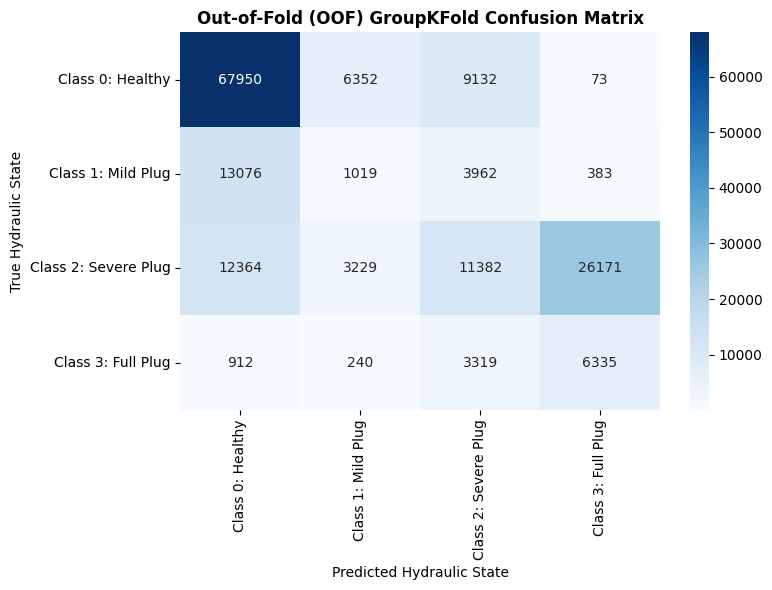

In [52]:
# Generate Global Classification Report
class_names = ['Class 0: Healthy', 'Class 1: Mild Plug', 'Class 2: Severe Plug', 'Class 3: Full Plug']
print("\n===== 5-FOLD CROSS-VALIDATED METRICS =====")
print(classification_report(oof_targets, oof_preds, target_names=class_names, digits=4))

# Plot Unified OOF Confusion Matrix
cm = confusion_matrix(oof_targets, oof_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, yticklabels=class_names)
plt.title('Out-of-Fold (OOF) GroupKFold Confusion Matrix', fontsize=12, fontweight='bold')
plt.xlabel('Predicted Hydraulic State')
plt.ylabel('True Hydraulic State')
plt.tight_layout()
plt.show()